### Tarea 2

In [1]:
import numpy as np
import time
import matplotlib.pyplot as plt


### Pregunta 2


In [31]:
def metodo_Jacobi(A, b, tol, max_iter):
    x0 = np.zeros_like(b)
    D = np.diag(np.diag(A))
    R = A - D
    D_inv = np.linalg.inv(D)

    x_new = D_inv @ (b - R @ x0)
    residuos = np.linalg.norm(A @ x_new - b)

    iteration = 1
    while np.linalg.norm(A @ x_new - b) / np.linalg.norm(b) > tol and iteration < max_iter:
        x_new = D_inv @ (b - R @ x_new)
        iteration += 1

        residuos = np.linalg.norm(A @ x_new - b)
    return x_new, residuos, iteration

def convergencia_Jacobi(A):
    D = np.diag(np.diag(A))
    R = A - D
    D_inv = np.linalg.inv(D)
    spectral_radius = max(abs(np.linalg.eigvals(D_inv @ R)))
    return spectral_radius < 1

In [32]:
A = np.array([
    [10, -1,  2],
    [-1, 11, -1],
    [ 2, -1, 10]
], dtype=float)

b = np.array([6, 25, -11], dtype=float)

tolerance = 1e-10
max_iterations = 100

solution, residuos, iteration = metodo_Jacobi(A, b, tolerance, max_iterations)
print("Solución aproximada:", solution)
print("Verificación (Ax):", A @ solution)
print(f"Residuo: {residuos}")
print(f"Número de iteraciones: {iteration}")

if convergencia_Jacobi(A):
    print("El método de Jacobi converge para esta matriz.")
else:
    print("El método de Jacobi no converge para esta matriz.")


print("Solución exacta:", np.linalg.solve(A, b))

print("Error de la solución aproximada:", np.linalg.norm(solution - np.linalg.solve(A, b)))

inicio = time.perf_counter()
x_jacobi, residuos_jacobi, iteraciones_jacobi = metodo_Jacobi(A, b, tolerance, max_iterations)
tiempo_jacobi = time.perf_counter() - inicio

inicio = time.perf_counter()
x_numpy = np.linalg.solve(A, b)
tiempo_numpy = time.perf_counter() - inicio

print(f"Tiempo Jacobi: {tiempo_jacobi:.8f} s")
print(f"Tiempo NumPy:  {tiempo_numpy:.8f} s")
print(f"Error entre soluciones: {np.linalg.norm(x_jacobi - x_numpy):.2e}")



Solución aproximada: [ 1.04326923  2.26923077 -1.08173077]
Verificación (Ax): [  6.  25. -11.]
Residuo: 2.6389476145812664e-09
Número de iteraciones: 17
El método de Jacobi converge para esta matriz.
Solución exacta: [ 1.04326923  2.26923077 -1.08173077]
Error de la solución aproximada: 2.0417034397492213e-10
Tiempo Jacobi: 0.00282830 s
Tiempo NumPy:  0.00051610 s
Error entre soluciones: 2.04e-10


In [33]:
n = 50
np.random.seed(42)

A = np.random.uniform(-1, 1, (n, n))
np.fill_diagonal(A, np.sum(np.abs(A), axis=1) + 1)

b = np.random.uniform(-10, 10, n)

tolerance = 1e-10
max_iterations = 1000

solution, residuos, iteration = metodo_Jacobi(A, b, tolerance, max_iterations)
print("Solución aproximada:", solution)
print("Verificación (Ax):", A @ solution)
print(f"Residuo: {residuos}")
print(f"Número de iteraciones: {iteration}")

if convergencia_Jacobi(A):
    print("El método de Jacobi converge para esta matriz.")
else:
    print("El método de Jacobi no converge para esta matriz.")

print("Solución exacta:", np.linalg.solve(A, b))
print("Error de la solución aproximada:", np.linalg.norm(solution - np.linalg.solve(A, b)))

inicio = time.perf_counter()
x_jacobi, residuos_jacobi, iteraciones_jacobi = metodo_Jacobi(A, b, tolerance, max_iterations)
tiempo_jacobi = time.perf_counter() - inicio

inicio = time.perf_counter()
x_numpy = np.linalg.solve(A, b)
tiempo_numpy = time.perf_counter() - inicio

print(f"Tiempo Jacobi: {tiempo_jacobi:.8f} s")
print(f"Tiempo NumPy:  {tiempo_numpy:.8f} s")
print(f"Error entre soluciones: {np.linalg.norm(x_jacobi - x_numpy):.2e}")


Solución aproximada: [ 2.10163564e-01  1.73464826e-01  4.75457467e-02  3.67760639e-01
 -2.27884662e-01 -3.30252272e-01  3.30857750e-01  3.92877870e-03
  2.39103793e-01  2.73305121e-01 -3.68578780e-01  2.94637299e-01
 -1.00668037e-01 -1.48546920e-02  1.21984881e-01  2.95656477e-01
 -3.95398984e-01 -6.83917956e-02  2.08538761e-01  1.66845953e-01
  7.15872421e-02 -3.69817061e-01 -1.38626359e-01 -3.75265299e-02
  1.90126108e-01 -1.68028609e-01 -2.13448833e-01  4.09880318e-01
 -3.69147833e-01  4.64942258e-01  2.21549772e-01  1.94047615e-01
 -1.69920509e-01 -3.80484250e-01  5.80062336e-02  2.62707552e-01
  1.54890336e-01 -3.44317353e-01  2.41317129e-01  2.29825066e-01
  1.34877726e-01  2.33424664e-01  2.81298317e-01  2.31111121e-02
 -2.42353509e-01 -2.99723319e-04 -2.33653254e-01 -1.38683331e-01
 -1.17513363e-01 -3.70471718e-01]
Verificación (Ax): [ 6.55037844  5.29055589  1.47057903  9.12094287 -5.99050969 -7.81471579
  7.07923934 -1.21700367  6.93937708  7.8618041  -8.75084813  7.66929526


In [34]:

# Ejemplo 3: Sistema de 100 ecuaciones

n = 100
np.random.seed(42)

A = np.random.uniform(-1, 1, (n, n))
np.fill_diagonal(A, np.sum(np.abs(A), axis=1) + 1)

b = np.random.uniform(-10, 10, n)

tolerance = 1e-10
max_iterations = 1000

solution, residuos, iteration = metodo_Jacobi(A, b, tolerance, max_iterations)
print("Solución aproximada:", solution)
print("Verificación (Ax):", A @ solution)
print(f"Residuo: {residuos}")
print(f"Número de iteraciones: {iteration}")

if convergencia_Jacobi(A):
    print("El método de Jacobi converge para esta matriz.")
else:
    print("El método de Jacobi no converge para esta matriz.")

print("Solución exacta:", np.linalg.solve(A, b))
print("Error de la solución aproximada:", np.linalg.norm(solution - np.linalg.solve(A, b)))

inicio = time.perf_counter()
x_jacobi, residuos_jacobi, iteraciones_jacobi = metodo_Jacobi(A, b, tolerance, max_iterations)
tiempo_jacobi = time.perf_counter() - inicio

inicio = time.perf_counter()
x_numpy = np.linalg.solve(A, b)
tiempo_numpy = time.perf_counter() - inicio

print(f"Tiempo Jacobi: {tiempo_jacobi:.8f} s")
print(f"Tiempo NumPy:  {tiempo_numpy:.8f} s")
print(f"Error entre soluciones: {np.linalg.norm(x_jacobi - x_numpy):.2e}")


Solución aproximada: [-0.06509449 -0.05063716 -0.12328846  0.05590073  0.01270683  0.11298961
 -0.18837453  0.05517405  0.11519293  0.11526921  0.13222546  0.07452914
  0.15156633 -0.08166821 -0.00096219 -0.20021047 -0.19617225 -0.11202518
 -0.15128389 -0.08990186 -0.14159441 -0.17356187  0.15357613 -0.22173871
  0.07632196 -0.11324409  0.17983567  0.13420837  0.05390964  0.07002791
 -0.19465569  0.19657997  0.15099115  0.15184508  0.05780762 -0.07634416
  0.15615823 -0.08026938  0.03276515 -0.13117922  0.16236033 -0.15831018
 -0.12753257  0.02042513  0.09823242  0.04312754 -0.08509768 -0.19695836
  0.09658087  0.2069166   0.1319925  -0.01649461  0.16190523 -0.0310184
  0.02476639 -0.00054976 -0.02556741  0.09823205  0.01716029 -0.08810286
 -0.12333082 -0.17097128  0.03513497 -0.1185168  -0.15151345  0.06828806
  0.07270107  0.08334539  0.0179824   0.15779271  0.19472444  0.12873877
  0.06169232 -0.08470782  0.21436716 -0.08136349 -0.14314272 -0.00441339
 -0.15568852  0.1623977   0.037

### Análisis de resultados


Se implementó el método iterativo de Jacobi para resolver sistemas lineales de dimensiones $3\times3$, $50\times50$ y $100\times100$, utilizando una tolerancia de $10^{-10}$ y un máximo de 100 iteraciones para el primer sistema y 1000 para los restantes. La convergencia se verificó mediante el radio espectral de la matriz de iteración, comprobando que $\rho(D^{-1}R)<1$. Además, las matrices presentan dominancia diagonal estricta, garantizando la convergencia.


Los resultados obtenidos se resumen en la siguiente tabla:

| Dimensión | Iteraciones | Residuo | Error respecto a NumPy | Tiempo Jacobi (s) | Tiempo NumPy (s) |
|---|---:|---:|---:|---:|---:|
| \(3\times3\) | 17 | 2.64e-9 | 2.04e-10 | 0.002828 | 0.000516 |
| \(50\times50\) | 13 | 1.74e-9 | 6.28e-11 | 0.003620 | 0.000623 |
| \(100\times100\) | 11 | 1.37e-9 | 2.78e-11 | 0.005162 | 0.008919 |

En los tres casos, Jacobi alcanzó soluciones prácticamente idénticas a las obtenidas mediante `numpy.linalg.solve()`, con errores del orden de $10^{-10}$ o menores. El número de iteraciones disminuyó al aumentar la dimensión, lo que se relaciona con las características de las matrices generadas y no necesariamente con su tamaño.

Respecto al desempeño computacional, NumPy presentó menores tiempos para los sistemas de $3\times3$ y $50\times50$, mientras que Jacobi fue más rápido para el sistema de $100\times100$. Sin embargo, estas mediciones corresponden a ejecuciones individuales, por lo que pueden estar influenciadas por fluctuaciones del sistema y no permiten establecer una superioridad general de un método sobre otro.

En conclusión, el método de Jacobi mostró una convergencia satisfactoria y una precisión comparable con NumPy para los sistemas estudiados. Su desempeño depende de las propiedades de la matriz y de la implementación utilizada, por lo que se requieren mediciones repetidas para realizar una comparación de eficiencia más representativa.

Pregunta 3

In [6]:
A = np.array([
    [4.218613, 6.327917],
    [3.141592, 4.712390]
], dtype=float)

b = np.array([10.546530, 7.853982], dtype=float)

A_p = np.array([
    [4.218611, 6.327917],
    [3.141594, 4.712390]
], dtype=float)

b_p = np.array([10.546530, 7.853980], dtype=float)

x = np.linalg.solve(A, b)

x_p = np.linalg.solve(A_p, b_p)

print("Solución original:", x)
print("Solución perturbada:", x_p)

delta_x = np.linalg.norm(x - x_p)

error_relative = delta_x / np.linalg.norm(x)

print(f"Diferencia entre soluciones: {delta_x}")
print(f"Error relativo: {error_relative:.2e}")

valores_singulares = np.linalg.svd(A, compute_uv=False)

kappa = max(valores_singulares) / min(valores_singulares)

kappa_p = np.linalg.cond(A_p, 2)

print("Condicionamiento original:", kappa)
print("Condicionamiento perturbado:", kappa_p)


Solución original: [1. 1.]
Solución perturbada: [-5.  5.]
Diferencia entre soluciones: 7.211102552094726
Error relativo: 5.10e+00
Condicionamiento original: 5519262.907950279
Condicionamiento perturbado: 15531025.740958575



### Análisis de resultados

Para estudiar la sensibilidad de un sistema lineal frente a pequeñas perturbaciones, se resolvieron los sistemas original y perturbado mediante `numpy.linalg.solve()`, obteniendo los vectores solución $\mathbf{x}$ y $\mathbf{x}_p$, respectivamente.

La diferencia entre ambas soluciones se cuantificó utilizando la **norma euclidiana**, que permite medir la magnitud de un vector:

$$
\|\mathbf{x}\|_2=\sqrt{\sum_{i=1}^{n}x_i^2}
$$

A partir de esta definición, se calculó la diferencia absoluta entre las soluciones:

$$
\Delta x=\|\mathbf{x}_p-\mathbf{x}\|_2=7.2111
$$

Para evaluar la importancia de esta diferencia respecto de la solución original, se calculó el **cambio relativo**:

$$
e_{\mathrm{rel}}=\frac{\|\mathbf{x}_p-\mathbf{x}\|_2}{\|\mathbf{x}\|_2}=5.10
$$

Esto indica que la magnitud de la diferencia entre ambas soluciones corresponde aproximadamente al **510 % de la norma de la solución original**, a pesar de que las perturbaciones introducidas en los coeficientes son del orden de $10^{-6}$.

Para explicar este comportamiento, se calculó el **número de condicionamiento** mediante la norma euclidiana:

$$
\kappa_2(A)=\frac{\sigma_{\max}(A)}{\sigma_{\min}(A)}
$$

Donde $\sigma_{\max}$ y $\sigma_{\min}$ corresponden al mayor y menor valor singular de la matriz, respectivamente. Este cociente permite caracterizar la sensibilidad potencial del sistema frente a pequeñas variaciones en sus datos: cuanto mayor es su valor, mayor puede ser la amplificación de dichas perturbaciones.

Los resultados obtenidos fueron:

| Sistema | Número de condicionamiento |
|---|---:|
| Original | $5.5193\times10^6$ |
| Perturbado | $1.5531\times10^7$ |

Ambos valores son considerablemente mayores que uno, indicando que los sistemas están **mal condicionados**. Además, la matriz perturbada presenta un número de condicionamiento superior, lo que evidencia una mayor sensibilidad potencial frente a nuevas perturbaciones.


Por lo tanto, los resultados muestran que pequeñas modificaciones en los coeficientes de un sistema lineal pueden producir diferencias significativas en su solución cuando la matriz está mal condicionada. Esto no implica necesariamente que el algoritmo de resolución sea incorrecto, sino que el propio problema es sensible a variaciones en los datos de entrada.

Por lo tanto, el número de condicionamiento constituye una herramienta importante para evaluar la confiabilidad de las soluciones numéricas, especialmente en problemas de fluidodinámica computacional, donde los sistemas lineales pueden involucrar numerosas incógnitas y errores asociados a la discretización y al cálculo numérico.


### Pregunta 4


In [39]:
def F(x, y):
    return np.array([x**2 - y**2 - 2*np.cos(x), x*y + np.sin(x) - y**3])

def J(x, y):
    return np.array([[2*x + 2*np.sin(x), -2*y], [y + np.cos(x), x - 3*y**2]])

def newton_raphson(F, J, x, tol=1e-10, max_iter=100):

    i = 0
    while i < max_iter and np.linalg.norm(F(x[0], x[1])) > tol:

        F_val = F(x[0], x[1])
        J_val = J(x[0], x[1])

        delta_x = np.linalg.solve(J_val, -F_val)

        x = x + delta_x

        i += 1

    print("Solución aproximada:", x)
    print("Residuo final:", np.linalg.norm(F(x[0], x[1])))
    print("Número de iteraciones:", i)

    return x, i


In [41]:
puntos_iniciales = [
    np.array([1.0, 1.0]),
    np.array([-1.0, -1.0]),
    np.array([2.0, 2.0])
]

for i in range(len(puntos_iniciales)):
    print(f"\nPunto inicial {i+1}: {puntos_iniciales[i]}")
    solucion, iteraciones = newton_raphson(F, J, puntos_iniciales[i])



Punto inicial 1: [1. 1.]
Solución aproximada: [1.51646198 1.48021678]
Residuo final: 1.0853948580769779e-12
Número de iteraciones: 6

Punto inicial 2: [-1. -1.]
Solución aproximada: [-1.11601715 -0.6057775 ]
Residuo final: 2.7755575615628914e-16
Número de iteraciones: 5

Punto inicial 3: [2. 2.]
Solución aproximada: [1.51646198 1.48021678]
Residuo final: 1.539914254355022e-14
Número de iteraciones: 5



### Análisis de resultados

Para resolver el sistema de ecuaciones no lineales se implementó el método iterativo de Newton-Raphson, considerando las funciones:

$$
\mathbf{F}(x,y)=
\begin{bmatrix}
x^2-y^2-2\cos(x)\\
xy+\sin(x)-y^3
\end{bmatrix}
$$

A diferencia de un sistema lineal, las incógnitas aparecen en términos no lineales, por lo que se utiliza una **linealización local mediante una expansión de Taylor de primer orden** para obtener aproximaciones sucesivas a una raíz.

Para ello, se construyó la **matriz jacobiana**, que contiene las derivadas parciales de cada función respecto de las incógnitas:

$$
J(x,y)=
\begin{bmatrix}
2x+2\sin(x)&-2y\\
y+\cos(x)&x-3y^2
\end{bmatrix}
$$

En cada iteración, el método determina una corrección $\Delta\mathbf{x}^{(k)}$ resolviendo el sistema lineal:

$$
J(\mathbf{x}^{(k)})\Delta\mathbf{x}^{(k)}
=-\mathbf{F}(\mathbf{x}^{(k)})
$$

Posteriormente, se actualiza la aproximación mediante:

$$
\mathbf{x}^{(k+1)}
=\mathbf{x}^{(k)}+\Delta\mathbf{x}^{(k)}
$$

Para resolver el sistema lineal de cada iteración se utilizó `numpy.linalg.solve()`, evitando calcular explícitamente la inversa del jacobiano.

Como **criterio de convergencia**, se utilizó la norma euclidiana del residuo:

$$
r=\|\mathbf{F}(\mathbf{x}^{(k)})\|_2<10^{-10}
$$

Esta condición permite verificar que ambas ecuaciones se satisfacen con una precisión determinada. Adicionalmente, se estableció un máximo de 100 iteraciones para evitar una ejecución indefinida si el método no converge.

Con el objetivo de analizar la influencia de la aproximación inicial, se resolvió el sistema utilizando tres puntos de partida diferentes. Los resultados obtenidos fueron:

| Punto inicial | Solución aproximada $(x,y)$ | Iteraciones | Residuo final |
|---|---|---:|---:|
| $(1,1)$ | $(1.516462,\;1.480217)$ | 6 | $1.09\times10^{-12}$ |
| $(-1,-1)$ | $(-1.116017,\;-0.605778)$ | 5 | $2.78\times10^{-16}$ |
| $(2,2)$ | $(1.516462,\;1.480217)$ | 5 | $1.54\times10^{-14}$ |

En los tres casos se alcanzó la tolerancia establecida, obteniendo residuos inferiores a $10^{-10}$ en un máximo de seis iteraciones. Esto demuestra una convergencia satisfactoria para los puntos iniciales estudiados.

Se observa que los puntos iniciales $(1,1)$ y $(2,2)$ convergen a la misma solución, mientras que $(-1,-1)$ conduce a una raíz diferente. Este comportamiento evidencia que **Newton-Raphson es un método de convergencia local**, cuyo resultado depende de la aproximación inicial. Por lo tanto, encontrar una solución no garantiza haber identificado todas las raíces del sistema.

Asimismo, las diferencias en el número de iteraciones muestran que el punto inicial influye en la rapidez de convergencia. Aunque en los casos evaluados el método convergió rápidamente, no se garantiza este comportamiento para cualquier aproximación inicial, especialmente cuando el jacobiano es singular o está mal condicionado.

En conclusión, la implementación permitió resolver satisfactoriamente el sistema no lineal mediante linealizaciones sucesivas. Los resultados confirman la importancia de la matriz jacobiana, del criterio de convergencia y de la selección del punto inicial para obtener soluciones numéricas confiables.


### Pregunta 5


In [48]:
x = np.array([1.0, 1.3, 1.6, 1.9, 2.2])
y = np.array([0.1411, -0.6878, -0.9962, -0.5507, 0.3115])


n = len(x)
tabla = np.zeros((n, n))
tabla[:, 0] = y

for j in range(1, n):
    for i in range(n - j):
        tabla[i, j] = (tabla[i + 1, j - 1] - tabla[i, j - 1]) / (x[i + j] - x[i])

print("Tabla de diferencias divididas:")
print(tabla)

a = tabla[0, :]
print("Coeficientes del polinomio de Newton:", a)


def newton_polynomial(x, a, x_data):
    p = (a[0]
         + a[1] * (x - x_data[0])
         + a[2] * (x - x_data[0]) * (x - x_data[1])
         + a[3] * (x - x_data[0]) * (x - x_data[1]) * (x - x_data[2])
         + a[4] * (x - x_data[0]) * (x - x_data[1]) * (x - x_data[2]) * (x - x_data[3]))
    return p


for i in range(len(x)):
    p = newton_polynomial(x[i], a, x)
    print(f"x = {x[i]:.1f}, y original = {y[i]:.4f}, P(x) = {p:.4f}")

print(newton_polynomial(1.3, a, x))



Tabla de diferencias divididas:
[[ 0.1411     -2.763       2.89166667  1.44074074 -2.93518519]
 [-0.6878     -1.028       4.18833333 -2.08148148  0.        ]
 [-0.9962      1.485       2.315       0.          0.        ]
 [-0.5507      2.874       0.          0.          0.        ]
 [ 0.3115      0.          0.          0.          0.        ]]
Coeficientes del polinomio de Newton: [ 0.1411     -2.763       2.89166667  1.44074074 -2.93518519]
x = 1.0, y original = 0.1411, P(x) = 0.1411
x = 1.3, y original = -0.6878, P(x) = -0.6878
x = 1.6, y original = -0.9962, P(x) = -0.9962
x = 1.9, y original = -0.5507, P(x) = -0.5507
x = 2.2, y original = 0.3115, P(x) = 0.3115
-0.6878


In [49]:
x5 = 2.3
y5 = np.sin(x5)

p4_x5 = newton_polynomial(x5, a, x)

a5 = (y5 - p4_x5) / np.prod(x5 - x)

x_new = np.append(x, x5)
y_new = np.append(y, y5)
a_new = np.append(a, a5)

def newton_polynomial_5(t, a, x_data):
    p = (a[0]
         + a[1] * (t - x_data[0])
         + a[2] * (t - x_data[0]) * (t - x_data[1])
         + a[3] * (t - x_data[0]) * (t - x_data[1]) * (t - x_data[2])
         + a[4] * (t - x_data[0]) * (t - x_data[1]) * (t - x_data[2]) * (t - x_data[3])
         + a[5] * (t - x_data[0]) * (t - x_data[1]) * (t - x_data[2]) * (t - x_data[3]) * (t - x_data[4]))
    return p

print("\nVerificación del nuevo polinomio:")
for i in range(len(x_new)):
    p = newton_polynomial_5(x_new[i], a_new, x_new)
    print(f"x = {x_new[i]:.1f}, y original = {y_new[i]:.6f}, P5(x) = {p:.6f}")

error = np.max(np.abs(newton_polynomial_5(x_new, a_new, x_new) - y_new))
print("\nError máximo:", error)



Verificación del nuevo polinomio:
x = 1.0, y original = 0.141100, P5(x) = 0.141100
x = 1.3, y original = -0.687800, P5(x) = -0.687800
x = 1.6, y original = -0.996200, P5(x) = -0.996200
x = 1.9, y original = -0.550700, P5(x) = -0.550700
x = 2.2, y original = 0.311500, P5(x) = 0.311500
x = 2.3, y original = 0.745705, P5(x) = 0.745705

Error máximo: 4.440892098500626e-16


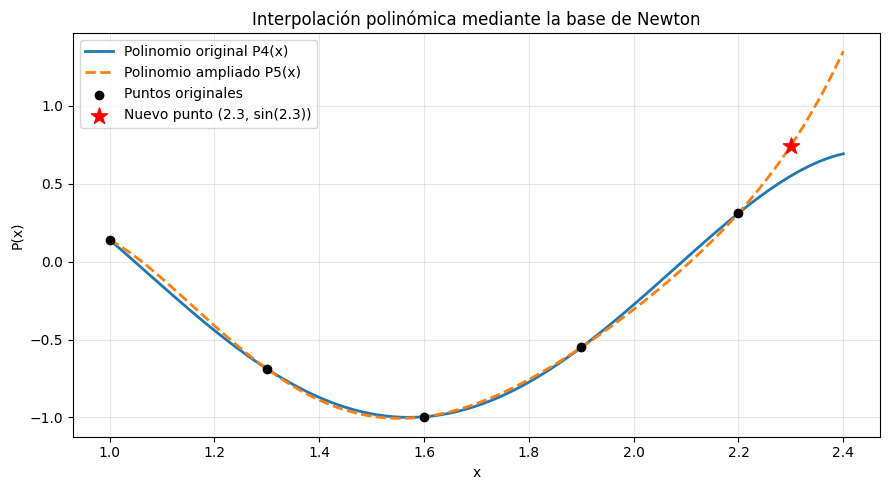

In [52]:
x_graf = np.linspace(1.0, 2.4, 500)

p4 = newton_polynomial(x_graf, a, x)
p5 = newton_polynomial_5(x_graf, a_new, x_new)

plt.figure(figsize=(9, 5))

plt.plot(x_graf, p4, label="Polinomio original P4(x)", linewidth=2)
plt.plot(x_graf, p5, label="Polinomio ampliado P5(x)", linewidth=2, linestyle="--")

plt.scatter(x, y, color="black", label="Puntos originales", zorder=3)
plt.scatter(x5, y5, color="red", marker="*", s=150,
            label="Nuevo punto (2.3, sin(2.3))", zorder=4)

plt.xlabel("x")
plt.ylabel("P(x)")
plt.title("Interpolación polinómica mediante la base de Newton")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



### Análisis de resultados

Para resolver el problema de interpolación se utilizó la **base polinómica de Newton**, que permite construir un polinomio que pasa exactamente por un conjunto de puntos conocidos. A diferencia de la base canónica, esta formulación facilita la incorporación de nuevos puntos sin necesidad de recalcular los coeficientes anteriores.

El polinomio interpolante se expresa como:

$$
P_n(x)=\sum_{k=0}^{n}a_k\prod_{j=0}^{k-1}(x-x_j)
$$

Donde los coeficientes $a_k$ se obtienen mediante **diferencias divididas**, calculadas recursivamente según:

$$
f[x_i,\ldots,x_{i+k}]
=
\frac{f[x_{i+1},\ldots,x_{i+k}]-f[x_i,\ldots,x_{i+k-1}]}
{x_{i+k}-x_i}
$$

Esta expresión permite construir una tabla triangular de diferencias divididas, cuya primera fila contiene los coeficientes del polinomio de Newton.

#### Polinomio original

Utilizando los cinco puntos entregados, se obtuvo un polinomio de grado 4 con los siguientes coeficientes:

| Coeficiente | Valor |
|---|---:|
| $a_0$ | 0.141100 |
| $a_1$ | -2.763000 |
| $a_2$ | 2.891667 |
| $a_3$ | 1.440741 |
| $a_4$ | -2.935185 |

Por lo tanto, el polinomio interpolante queda expresado en la base de Newton como:

$$
\begin{aligned}
P_4(x)={}&0.1411-2.763(x-1)\\
&+2.891667(x-1)(x-1.3)\\
&+1.440741(x-1)(x-1.3)(x-1.6)\\
&-2.935185(x-1)(x-1.3)(x-1.6)(x-1.9)
\end{aligned}
$$

La evaluación del polinomio en los cinco nodos originales reprodujo correctamente todos los valores entregados, verificando que se cumple la condición de interpolación $P_4(x_i)=y_i$.

#### Incorporación del sexto punto

Posteriormente, se añadió el punto $(2.3,\sin(2.3))$, cuyo valor es aproximadamente $0.745705$. Para incorporar este dato, se mantuvieron los cinco coeficientes originales y se calculó únicamente un nuevo coeficiente $a_5$, utilizando:

$$
a_5=\frac{\sin(2.3)-P_4(2.3)}
{\prod_{j=0}^{4}(2.3-x_j)}
$$

Se obtuvo:

$$
P_4(2.3)=0.551033,\qquad a_5=5.348129
$$

De esta manera, el nuevo polinomio de grado 5 se expresa como:

$$
P_5(x)=P_4(x)+5.348129(x-1)(x-1.3)(x-1.6)(x-1.9)(x-2.2)
$$

El término adicional se anula en los cinco nodos originales, por lo que el nuevo polinomio conserva sus valores interpolados. En cambio, en $x=2.3$ permite ajustar el resultado al sexto punto incorporado.

La verificación numérica entregó un **error máximo de interpolación** de:

$$
E_{\max}=\max_i|P_5(x_i)-y_i|=4.44\times10^{-16}
$$

Este valor es prácticamente nulo y corresponde al orden de los errores de redondeo asociados a la aritmética de punto flotante.

En el gráfico se comparan los polinomios $P_4(x)$ y $P_5(x)$ junto con los puntos utilizados para su construcción. Se observa que ambas curvas coinciden en los cinco nodos originales, mientras que el polinomio ampliado se modifica para pasar por el sexto punto.

La diferencia entre ambos polinomios resulta especialmente relevante cerca de $x=2.3$, donde $P_4(2.3)\approx0.551033$, mientras que $P_5(2.3)\approx0.745705$.

Estos resultados demuestran que la base de Newton permite ampliar un polinomio interpolante de manera eficiente, conservando los coeficientes previamente calculados. Además, se verifica que ambos polinomios cumplen las condiciones de interpolación correspondientes a sus respectivos conjuntos de puntos.

Finalmente, es importante distinguir entre la exactitud de la interpolación en los nodos y la precisión de la aproximación entre ellos. Aunque el error en los puntos conocidos sea prácticamente nulo, esto no garantiza que el polinomio represente con igual precisión una función fuera de dichos puntos.


#### Pregunta 6

Método de cuadratura de orden 0

In [57]:
def f(x, y):
    return np.cos(x + y)**2 + np.sin(x*y)**2

a = np.sqrt(2)
b = 3 / np.sqrt(2)

N = 50

def dentro_elipse(x, y):
    return (x/a)**2 + (y/b)**2 <= 1


dx = 2*a / N
dy = 2*b / N

x_centros = np.linspace(-a + dx/2, a - dx/2, N)
y_centros = np.linspace(-b + dy/2, b - dy/2, N)

X, Y = np.meshgrid(x_centros, y_centros)

mascara = dentro_elipse(X, Y)

dA = dx * dy

Z = f(X, Y)

V0 = np.sum(Z[mascara]) * dA

print("Volumen aproximado (orden 0):", V0)
print("Elementos considerados:", np.sum(mascara))

area_malla = np.sum(mascara) * dA
area_exacta = np.pi * a * b

print("Área aproximada:", area_malla)
print("Área exacta:", area_exacta)
print("Error relativo del área:",
      abs(area_malla - area_exacta) / area_exacta)


Volumen aproximado (orden 0): 6.6846740206888215
Elementos considerados: 1976
Área aproximada: 9.4848
Área exacta: 9.42477796076938
Error relativo del área: 0.006368536158672615


Método de cuadratura de Gauss

In [ ]:
puntos, pesos = np.polynomial.legendre.leggauss(2)

V_gauss = 0.0

for xc, yc in zip(X[mascara], Y[mascara]):

    for i in range(len(puntos)):
        for j in range(len(puntos)):

            x_gauss = xc + (dx / 2) * puntos[i]
            y_gauss = yc + (dy / 2) * puntos[j]

            V_gauss += pesos[i] * pesos[j] * f(x_gauss, y_gauss) * dA / 4

print("Volumen (orden 0):", V0)
print("Volumen (Gauss-Legendre):", V_gauss)
print("Diferencia absoluta:", abs(V_gauss - V0))
print("Diferencia relativa:", abs(V_gauss - V0) / abs(V_gauss))


Volumen (orden 0): 6.6846740206888215
Volumen (Gauss-Legendre): 6.687020864088579
Diferencia absoluta: 0.0023468433997573257
Diferencia relativa: 0.00035095499886363726


In [60]:
N_valores = [25, 50, 100, 200]

puntos, pesos = np.polynomial.legendre.leggauss(2)

resultados = []

for N in N_valores:

    dx = 2*a / N
    dy = 2*b / N
    dA = dx * dy

    x_centros = np.linspace(-a + dx/2, a - dx/2, N)
    y_centros = np.linspace(-b + dy/2, b - dy/2, N)

    X, Y = np.meshgrid(x_centros, y_centros)

    mascara = dentro_elipse(X, Y)

    V0 = np.sum(f(X, Y)[mascara]) * dA

    V_gauss = 0.0

    for xc, yc in zip(X[mascara], Y[mascara]):
        for i in range(len(puntos)):
            for j in range(len(puntos)):

                x_gauss = xc + (dx/2) * puntos[i]
                y_gauss = yc + (dy/2) * puntos[j]

                V_gauss += (
                    pesos[i] * pesos[j]
                    * f(x_gauss, y_gauss) * dA/4
                )

    diferencia = abs(V_gauss - V0)
    diferencia_relativa = diferencia / abs(V_gauss)

    area_malla = np.sum(mascara) * dA
    error_area = abs(area_malla - np.pi*a*b) / (np.pi*a*b)

    resultados.append([
        N, V0, V_gauss, diferencia_relativa, error_area
    ])

# Mostrar resultados
print(f"{'N':>5} {'Orden 0':>14} {'Gauss':>14} {'Dif. rel. (%)':>15} {'Error área (%)':>16}")

for N, V0, V_gauss, dif_rel, error_area in resultados:
    print(f"{N:5d} {V0:14.8f} {V_gauss:14.8f} {100*dif_rel:15.6f} {100*error_area:16.6f}")


    N        Orden 0          Gauss   Dif. rel. (%)   Error área (%)
   25     6.51301249     6.52305218        0.153911         0.381738
   50     6.68467402     6.68702086        0.035095         0.636854
  100     6.62516838     6.62575995        0.008928         0.076628
  200     6.62625602     6.62640332        0.002223         0.038431


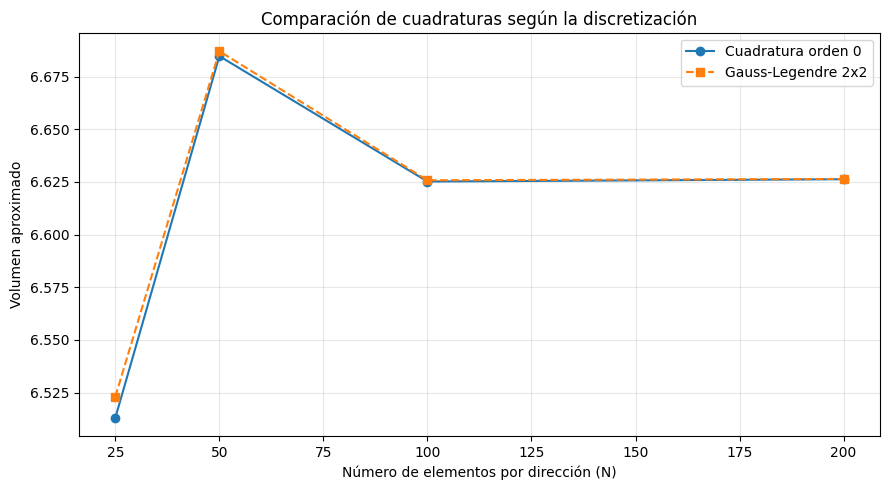

In [61]:
resultados = np.array(resultados)

N_graf = resultados[:, 0]
V0_graf = resultados[:, 1]
V_gauss_graf = resultados[:, 2]

plt.figure(figsize=(9, 5))

plt.plot(N_graf, V0_graf, "o-", label="Cuadratura orden 0")
plt.plot(N_graf, V_gauss_graf, "s--", label="Gauss-Legendre 2x2")

plt.xlabel("Número de elementos por dirección (N)")
plt.ylabel("Volumen aproximado")
plt.title("Comparación de cuadraturas según la discretización")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



### Análisis de resultados

Para calcular el volumen bajo la superficie se realizó una integración numérica bidimensional de la función:

$$
f(x,y)=\cos^2(x+y)+\sin^2(xy)
$$

sobre el dominio elíptico:

$$
\Omega=\left\{(x,y)\in\mathbb{R}^2:
\frac{x^2}{2}+\frac{y^2}{4.5}\leq1\right\}
$$

El volumen corresponde a la integral:

$$
V=\iint_\Omega f(x,y)\,dA
$$

Para aproximarla, se discretizó el rectángulo que contiene la elipse mediante una malla uniforme de $N\times N$ elementos. Se seleccionaron aquellos cuyos centros pertenecen al dominio, utilizando una condición geométrica. Esta aproximación introduce un **error de cobertura**, debido a que la frontera curva de la elipse se representa mediante elementos rectangulares.

#### Cuadratura de orden 0

El primer procedimiento corresponde al método intuitivo o cuadratura de orden 0, donde la función se considera constante dentro de cada elemento, evaluándola en su centro.

El volumen se aproxima mediante:

$$
V_0\approx\sum_{e\in\Omega_h}f(x_e,y_e)\Delta A
$$

Donde $(x_e,y_e)$ representa el centro del elemento, $\Delta A=\Delta x\Delta y$ es su área y $\Omega_h$ corresponde al conjunto de elementos seleccionados.

Este método requiere una sola evaluación de la función por elemento, lo que facilita su implementación y reduce el costo computacional.

#### Cuadratura de Gauss-Legendre

Como segundo procedimiento se implementó una cuadratura de Gauss-Legendre de **dos puntos por dirección**, equivalente a cuatro evaluaciones por elemento.

La aproximación utilizada es:

$$
V_G\approx\sum_{e\in\Omega_h}\frac{\Delta A}{4}
\sum_{i=1}^{2}\sum_{j=1}^{2}
w_iw_j f(x_{e,i},y_{e,j})
$$

Donde $w_i$ y $w_j$ son los pesos de Gauss, mientras que $(x_{e,i},y_{e,j})$ representan los puntos de evaluación transformados a cada elemento.

Los puntos y pesos se obtuvieron mediante `numpy.polynomial.legendre.leggauss()`, utilizando la misma discretización y los mismos elementos seleccionados que en el método de orden 0. De esta manera, se comparan las reglas de integración manteniendo constante la representación geométrica del dominio para cada valor de $N$.

#### Comparación de resultados

Inicialmente, para una discretización de $N=50$, se obtuvieron los siguientes volúmenes:

$$
V_0=6.684674,\qquad V_G=6.687021
$$

La diferencia relativa entre ambos métodos fue:

$$
e_{\mathrm{rel}}=\frac{|V_G-V_0|}{|V_G|}
=0.000351\approx0.0351\%
$$

Posteriormente, se evaluaron distintas resoluciones de malla para estudiar la influencia de la discretización:

| $N$ | Orden 0 | Gauss-Legendre | Diferencia relativa (%) | Error área (%) |
|---:|---:|---:|---:|---:|
| 25 | 6.513012 | 6.523052 | 0.153911 | 0.381738 |
| 50 | 6.684674 | 6.687021 | 0.035095 | 0.636854 |
| 100 | 6.625168 | 6.625760 | 0.008928 | 0.076628 |
| 200 | 6.626256 | 6.626403 | 0.002223 | 0.038431 |

Se observa que la **diferencia relativa entre los métodos disminuye progresivamente** al aumentar $N$, desde aproximadamente $0.154\%$ para $N=25$ hasta $0.0022\%$ para $N=200$. Esto indica que, al reducir el tamaño de los elementos, ambas reglas de integración entregan resultados cada vez más similares.

Sin embargo, los valores del volumen no presentan una evolución completamente monótona. En particular, para $N=50$ se obtiene un volumen mayor que para $N=100$ y $N=200$. Este comportamiento puede explicarse por el error de cobertura, ya que la selección de elementos según sus centros produce variaciones en la representación de la frontera elíptica.

Para evaluar este efecto, se comparó el área representada por la malla con el área exacta de la elipse:

$$
A_\Omega=\pi ab=3\pi\approx9.424778
$$

El error relativo del área se calculó mediante:

$$
e_A=\frac{|A_h-A_\Omega|}{A_\Omega}
$$

Los resultados muestran que este error tampoco disminuye de forma estrictamente monótona, aunque alcanza aproximadamente $0.0384\%$ para $N=200$.

En el gráfico de comparación se aprecia que ambas cuadraturas presentan una evolución similar con el refinamiento de la malla, y que sus resultados se aproximan entre sí para discretizaciones más finas.

Los resultados muestran que ambos métodos permiten aproximar satisfactoriamente la integral bidimensional, obteniendo diferencias cada vez menores al refinar la discretización.

La cuadratura de orden 0 destaca por su simplicidad y menor número de evaluaciones, mientras que Gauss-Legendre utiliza varios puntos ponderados dentro de cada elemento para representar con mayor precisión las variaciones de la función.

No obstante, como ambos métodos utilizan la misma aproximación rectangular del dominio, **la disminución de la diferencia entre ellos no garantiza por sí sola una mayor exactitud respecto del volumen verdadero**. El error de cobertura permanece como una fuente de incertidumbre compartida.

Por lo tanto, la precisión de una integración numérica bidimensional depende tanto de la regla de cuadratura seleccionada como de la discretización y representación geométrica del dominio.



#### Pregunta 7

In [2]:
def sistema(t, u):
    x1, x2, v1 = u

    dx1 = v1
    dx2 = (b3*v1 - k3*x2) / (b2 + b3)
    dv1 = (-(b1 - b3)*v1 - b3*dx2 - k1*x1) / m

    return np.array([dx1, dx2, dv1])


def runge_kutta_4(f, t0, tf, u0, h):

    t = np.arange(t0, tf + h/2, h)
    u = np.zeros((len(t), len(u0)))
    u[0] = u0

    for i in range(len(t) - 1):
        K1 = f(t[i], u[i])
        K2 = f(t[i] + h/2, u[i] + h*K1/2)
        K3 = f(t[i] + h/2, u[i] + h*K2/2)
        K4 = f(t[i] + h, u[i] + h*K3)

        u[i+1] = u[i] + h*(K1 + 2*K2 + 2*K3 + K4)/6

    return t, u


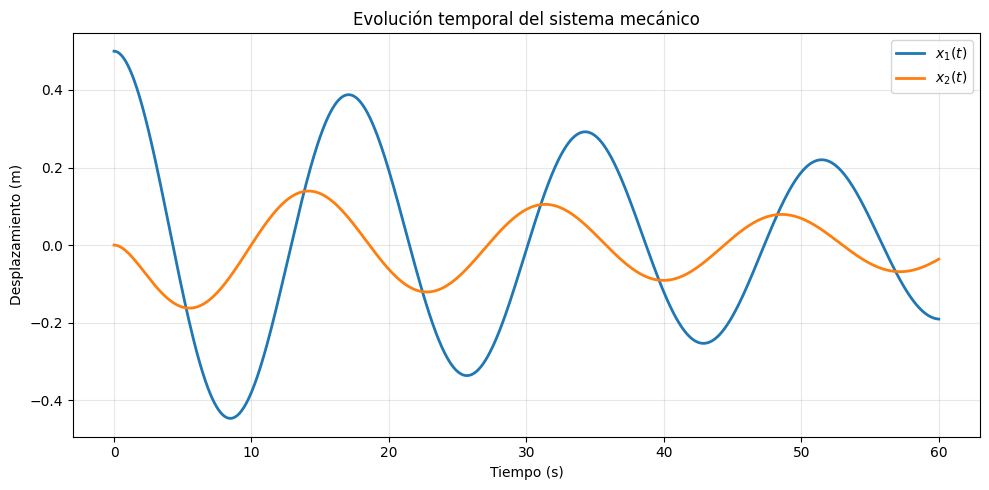

In [3]:
m = 10.0
k1 = 1.5
k3 = 1.4
b1 = 1.6
b2 = 0.8
b3 = 1.5

u0 = np.array([0.5, 0.0, 0.0])

t0 = 0.0
tf = 60.0
h = 0.05

t, u = runge_kutta_4(sistema, t0, tf, u0, h)

x1 = u[:, 0]
x2 = u[:, 1]


plt.figure(figsize=(10, 5))

plt.plot(t, x1, label="$x_1(t)$", linewidth=2)
plt.plot(t, x2, label="$x_2(t)$", linewidth=2)

plt.xlabel("Tiempo (s)")
plt.ylabel("Desplazamiento (m)")
plt.title("Evolución temporal del sistema mecánico")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
